# MCNN-AAPT + Spatial Pyramid Pooling (Google Colab)

End-to-end pipeline: **Dataset.zip (FASTA) → ProtT5 embeddings → pad/truncate to 1200 → Multi-window CNN with a Pyramid Pooling layer**.

**What changed in the model:** in the original MCNN every window branch (`Conv → global MaxPool`) kept only one max value per filter over the whole sequence.
Here each branch uses a **length-aware Spatial Pyramid Pooling (SPP)** layer: the *real* (unpadded) protein is split into 1, 2 and 4 equal regions
and max-pooled in each region, so the classifier also sees *where* along the sequence (N-terminal / middle / C-terminal) a motif fires.
Padding positions are masked out, so short proteins are not dominated by zero padding.

`PYRAMID_LEVELS = [1]` reproduces the original MCNN (global max pooling) for a baseline comparison.

**How to run**
1. `Runtime → Change runtime type → GPU (T4 is fine)`.
2. Run all cells. When asked, upload `Dataset.zip` (or drag it into the Files pane as `/content/Dataset.zip`, or put it in Google Drive and set `USE_DRIVE = True`).
3. Set `VALIDATION_MODE` to `"independent"` (train → Test set + SLC set) or `"cross"` (5-fold CV on Train+Test).

## 1. Install & imports

In [1]:
!pip -q install transformers sentencepiece

In [2]:
import os, gc, glob, math, re, time, zipfile, shutil, json
import numpy as np
import matplotlib.pyplot as plt
import torch
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, roc_auc_score, auc, confusion_matrix
from tqdm.auto import tqdm

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| PyTorch:", torch.__version__)
print("TF GPUs:", tf.config.list_physical_devices('GPU'))
print("Torch CUDA:", torch.cuda.is_available())

TensorFlow: 2.21.0 | Keras: 3.13.2 | PyTorch: 2.11.0+cu130
TF GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Torch CUDA: True


## 2. Parameters

In [3]:
# ---------------- Paths ----------------
USE_DRIVE   = False                                   # True -> read zip from / save results to Google Drive
DRIVE_DIR   = "/content/drive/MyDrive/MCNN-AAPT"      # used only if USE_DRIVE = True (put Dataset.zip here)
ZIP_PATH    = "/content/Dataset.zip"                  # where the uploaded zip lives
EXTRACT_DIR = "/content/data"                         # zip is extracted here
FEATURE_DIR = "/content/features/prottrans"           # per-protein ProtT5 embeddings cache (.npy)
RESULT_DIR  = "/content/results"

# ---------------- Data ----------------
MAX_SEQ_LENGTH = 1200        # pad / truncate every protein to this length
NUM_FEATURE    = 1024        # ProtT5-XL embedding size
CLASS_NAMES    = ["Other SATs", "Amino acids"]   # label 0, label 1

# ---------------- Model ----------------
WINDOW_SIZES   = [4, 8]
NUM_FILTER     = 128
NUM_HIDDEN     = 512
DROPOUT        = 0.7
PYRAMID_LEVELS = [1, 2, 4]   # SPP bins per level. [1] == original MCNN global max-pool
PYRAMID_POOL   = "max"       # "max" or "avg"

# ---------------- Training ----------------
BATCH_SIZE      = 3
EPOCHS          = 50
LEARNING_RATE   = 1e-3
K_FOLD          = 5
VALIDATION_MODE = "independent"   # "independent" or "cross"
SEED            = 42

keras.utils.set_random_seed(SEED)

## 3. Get the dataset zip (upload / Drive) and extract it

In [4]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    if not os.path.exists(ZIP_PATH) and os.path.exists(os.path.join(DRIVE_DIR, "Dataset.zip")):
        shutil.copy(os.path.join(DRIVE_DIR, "Dataset.zip"), ZIP_PATH)

if not os.path.exists(ZIP_PATH):
    from google.colab import files
    print("Please upload Dataset.zip ...")
    uploaded = files.upload()
    zip_name = [n for n in uploaded if n.lower().endswith(".zip")][0]
    if os.path.abspath(zip_name) != ZIP_PATH:
        shutil.move(zip_name, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(EXTRACT_DIR)

# Find the folder that contains "Amino acid", "Other SATs" and "SLC_Data"
# (works whether the zip has a top-level "Dataset/" folder or not)
DATA_ROOT = None
for root, dirs, _ in os.walk(EXTRACT_DIR):
    if {"Amino acid", "Other SATs", "SLC_Data"}.issubset(set(dirs)):
        DATA_ROOT = root
        break
assert DATA_ROOT is not None, "Could not find 'Amino acid', 'Other SATs' and 'SLC_Data' folders inside the zip"
print("DATA_ROOT =", DATA_ROOT)

DATA_ROOT = /content/data/Dataset


In [5]:
# split name -> list of (folder relative to DATA_ROOT, label)   label 1 = Amino acid, 0 = other
SPLITS = {
    "train": [("Amino acid/Train", 1), ("Other SATs/Train", 0)],
    "test":  [("Amino acid/Test", 1),  ("Other SATs/Test", 0)],
    "slc":   [("SLC_Data/Amino acid", 1), ("SLC_Data/Other SLC", 0)],
}

def read_fasta(path):
    with open(path) as f:
        seq = "".join(line.strip() for line in f if not line.startswith(">"))
    return os.path.splitext(os.path.basename(path))[0], seq.upper()

records = {}   # split -> list of dicts(id, seq, label)
for split, folders in SPLITS.items():
    records[split] = []
    for folder, label in folders:
        paths = sorted(glob.glob(os.path.join(DATA_ROOT, folder, "*.fasta")) +
                       glob.glob(os.path.join(DATA_ROOT, folder, "*.fa")))
        for p in paths:
            pid, seq = read_fasta(p)
            records[split].append({"id": pid, "seq": seq, "label": label})
        print(f"{split:5s} | {folder:22s} | label={label} | {len(paths)} proteins")

train | Amino acid/Train       | label=1 | 40 proteins
train | Other SATs/Train       | label=0 | 318 proteins
test  | Amino acid/Test        | label=1 | 10 proteins
test  | Other SATs/Test        | label=0 | 80 proteins
slc   | SLC_Data/Amino acid    | label=1 | 16 proteins
slc   | SLC_Data/Other SLC     | label=0 | 20 proteins


## 4. ProtT5 feature extraction (GPU, cached)
Each protein is embedded once with `Rostlab/prot_t5_xl_half_uniref50-enc` and saved as `FEATURE_DIR/<split>/<id>.npy` (L × 1024). Re-running skips proteins already done. With `USE_DRIVE = True` the cache is also copied to Drive so you never need to re-extract.

In [6]:
DRIVE_FEATURE_DIR = os.path.join(DRIVE_DIR, "features_prottrans") if USE_DRIVE else None
if USE_DRIVE and os.path.isdir(DRIVE_FEATURE_DIR) and not os.path.isdir(FEATURE_DIR):
    shutil.copytree(DRIVE_FEATURE_DIR, FEATURE_DIR)          # restore cache from Drive

def missing_ids():
    return [(s, r) for s in records for r in records[s]
            if not os.path.exists(os.path.join(FEATURE_DIR, s, r["id"] + ".npy"))]

todo = missing_ids()
print("Proteins to embed:", len(todo))

if todo:
    from transformers import T5EncoderModel, T5Tokenizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print("Embedding on", device)
    tokenizer = T5Tokenizer.from_pretrained("Rostlab/prot_t5_xl_half_uniref50-enc", do_lower_case=False)
    t5 = T5EncoderModel.from_pretrained("Rostlab/prot_t5_xl_half_uniref50-enc").to(device).eval()
    t5 = t5.half() if device.type == "cuda" else t5.float()

    @torch.no_grad()
    def embed(seq):
        seq = re.sub(r"[UZOB]", "X", seq)                    # rare amino acids -> X (ProtT5 convention)
        enc = tokenizer(" ".join(seq), add_special_tokens=True, return_tensors="pt").to(device)
        out = t5(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state
        return out[0, :len(seq)].float().cpu().numpy()     # drop </s> token -> (L, 1024)

    for split, r in tqdm(todo, desc="ProtT5"):
        os.makedirs(os.path.join(FEATURE_DIR, split), exist_ok=True)
        try:
            emb = embed(r["seq"])
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()                         # very long protein: embed only the part we keep
            print(f"OOM on {r['id']} (L={len(r['seq'])}), embedding first {MAX_SEQ_LENGTH} residues")
            emb = embed(r["seq"][:MAX_SEQ_LENGTH])
        np.save(os.path.join(FEATURE_DIR, split, r["id"] + ".npy"), emb.astype(np.float16))

    del t5; gc.collect(); torch.cuda.empty_cache()           # free GPU memory for TensorFlow

if USE_DRIVE:
    shutil.copytree(FEATURE_DIR, DRIVE_FEATURE_DIR, dirs_exist_ok=True)
print("Done. Still missing:", len(missing_ids()))

Proteins to embed: 484
Embedding on cuda:0


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/238k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/656 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.42GB            

model.safetensors: downloading bytes:           |  0.00B            

ProtT5:   0%|          | 0/484 [00:00<?, ?it/s]

Done. Still missing: 0


## 5. Build padded arrays
`X`: (N, 1200, 1024) float32, `L`: real length (≤ 1200) used by the pyramid layer to ignore padding, `y`: one-hot labels.

In [7]:
def build_split(split):
    recs = records[split]
    X = np.zeros((len(recs), MAX_SEQ_LENGTH, NUM_FEATURE), dtype=np.float32)
    L = np.zeros((len(recs), 1), dtype=np.int32)
    y = np.zeros((len(recs),), dtype=np.int32)
    for i, r in enumerate(recs):
        emb = np.load(os.path.join(FEATURE_DIR, split, r["id"] + ".npy"))[:MAX_SEQ_LENGTH]
        X[i, :len(emb)] = emb
        L[i, 0] = len(emb)
        y[i] = r["label"]
    return X, L, keras.utils.to_categorical(y, 2)

x_train, l_train, y_train = build_split("train")
x_test,  l_test,  y_test  = build_split("test")
x_slc,   l_slc,   y_slc   = build_split("slc")

for name, (x, l, y) in {"train": (x_train, l_train, y_train), "test": (x_test, l_test, y_test),
                        "slc": (x_slc, l_slc, y_slc)}.items():
    print(f"{name:5s} X={x.shape} positives={int(y[:,1].sum())} negatives={int(y[:,0].sum())}")

train X=(358, 1200, 1024) positives=40 negatives=318
test  X=(90, 1200, 1024) positives=10 negatives=80
slc   X=(36, 1200, 1024) positives=16 negatives=20


## 6. Model: MCNN + length-aware Spatial Pyramid Pooling

```
ProtT5 (1200×1024) ──┬─ Conv1D(w=4, 128) ─ SPP[1,2,4] ─ 7×128 ─┐
                     └─ Conv1D(w=8, 128) ─ SPP[1,2,4] ─ 7×128 ─┴─ concat ─ Dropout ─ Dense(512) ─ Dense(2, softmax)
protein length ──────────────────────────┘ (masks padding, defines bin borders)
```

In [8]:
@keras.saving.register_keras_serializable(package="mcnn")
class PyramidPooling1D(layers.Layer):
    # Length-aware Spatial Pyramid Pooling over the sequence axis.
    # inputs = [features (B, T, C), protein_length (B, 1)]
    # For each level n, the valid part of the sequence is split into n equal bins and each bin is pooled.
    # Output: (B, sum(levels) * C)

    def __init__(self, levels=(1, 2, 4), window_size=1, pool="max", **kwargs):
        super().__init__(**kwargs)
        self.levels = list(levels)
        self.window_size = int(window_size)
        self.pool = pool

    def call(self, inputs):
        x, length = inputs
        T = tf.shape(x)[1]
        # number of valid conv outputs = protein_length - window + 1 ('valid' padding)
        valid_len = tf.cast(tf.reshape(length, [-1, 1]), tf.float32) - (self.window_size - 1)
        valid_len = tf.maximum(valid_len, 1.0)                                 # (B, 1)
        pos = tf.cast(tf.range(T), tf.float32)[tf.newaxis, :]                  # (1, T)
        valid = pos < valid_len                                                # (B, T)

        pooled = []
        for n in self.levels:
            bin_id = tf.minimum(tf.cast(tf.floor(pos * n / valid_len), tf.int32), n - 1)  # (B, T)
            mask = tf.logical_and(tf.one_hot(bin_id, n, on_value=True, off_value=False, dtype=tf.bool),
                                  valid[:, :, tf.newaxis])                     # (B, T, n)
            mask = mask[:, :, :, tf.newaxis]                                   # (B, T, n, 1)
            xe = x[:, :, tf.newaxis, :]                                        # (B, T, 1, C)
            if self.pool == "max":
                p = tf.reduce_max(tf.where(mask, xe, tf.fill(tf.shape(xe), -1e9)), axis=1)  # (B, n, C)
                p = tf.where(p <= -1e9, tf.zeros_like(p), p)                   # empty bin -> 0
            else:
                m = tf.cast(mask, x.dtype)
                p = tf.reduce_sum(xe * m, axis=1) / tf.maximum(tf.reduce_sum(m, axis=1), 1.0)
            pooled.append(tf.reshape(p, [-1, n * x.shape[-1]]))
        return tf.concat(pooled, axis=-1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0][0], sum(self.levels) * input_shape[0][-1])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"levels": self.levels, "window_size": self.window_size, "pool": self.pool})
        return cfg


def build_mcnn_pyramid():
    seq_in = keras.Input(shape=(MAX_SEQ_LENGTH, NUM_FEATURE), name="embeddings")
    len_in = keras.Input(shape=(1,), dtype="int32", name="length")

    branches = []
    for w in WINDOW_SIZES:
        c = layers.Conv1D(NUM_FILTER, w, padding="valid", activation="relu",
                          kernel_initializer="glorot_uniform",
                          bias_initializer=keras.initializers.Constant(0.1),
                          name=f"conv_w{w}")(seq_in)
        p = PyramidPooling1D(PYRAMID_LEVELS, window_size=w, pool=PYRAMID_POOL, name=f"pyramid_w{w}")([c, len_in])
        branches.append(p)

    x = layers.Concatenate(name="concat")(branches) if len(branches) > 1 else branches[0]
    x = layers.Dropout(DROPOUT)(x)
    x = layers.Dense(NUM_HIDDEN, activation="relu", kernel_initializer="glorot_uniform",
                     bias_initializer=keras.initializers.Constant(0.1), name="fc1")(x)
    out = layers.Dense(2, activation="softmax", kernel_regularizer=keras.regularizers.l2(1e-3), name="fc2")(x)

    model = keras.Model([seq_in, len_in], out, name="MCNN_Pyramid")
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

build_mcnn_pyramid().summary()

Model: "MCNN_Pyramid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ embeddings          │ (None, 1200,      │          0 │ -                 │
│ (InputLayer)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_w4 (Conv1D)    │ (None, 1197, 128) │    524,416 │ embeddings[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ length (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_w8 (Conv1D)    │ (None, 1193, 128) │  1,048,704 │ embeddings[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pyramid_w4          │ (None, 896)       │          0 │ conv_w4[0][0],    │
│ (PyramidPooling1D)  │                   │            │ length[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pyramid_w8          │ (None, 896)       │          0 │ conv_w8[0][0],    │
│ (PyramidPooling1D)  │                   │            │ length[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, 1792)      │          0 │ pyramid_w4[0][0], │
│ (Concatenate)       │                   │            │ pyramid_w8[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1792)      │          0 │ concat[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fc1 (Dense)         │ (None, 512)       │    918,016 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fc2 (Dense)         │ (None, 2)         │      1,026 │ fc1[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,492,162 (9.51 MB)

 Trainable params: 2,492,162 (9.51 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Evaluation helper

In [9]:
def evaluate(model, x, l, y, title=""):
    prob = model.predict({"embeddings": x, "length": l}, batch_size=16, verbose=0)[:, 1]
    y_true = y[:, 1].astype(int)
    y_pred = (prob >= 0.5).astype(int)
    TN, FP, FN, TP = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    Sens = TP / (TP + FN) if TP + FN else 0.0
    Spec = TN / (TN + FP) if TN + FP else 0.0
    Acc  = (TP + TN) / (TP + TN + FP + FN)
    den  = math.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
    MCC  = (TP * TN - FP * FN) / den if den else 0.0
    F1   = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) else 0.0
    AUC  = roc_auc_score(y_true, prob) if len(set(y_true)) > 1 else float("nan")
    res = dict(TP=int(TP), FP=int(FP), TN=int(TN), FN=int(FN), Sens=Sens, Spec=Spec, Acc=Acc, MCC=MCC, AUC=AUC, F1=F1)
    print(f"{title} TP={TP}, FP={FP}, TN={TN}, FN={FN}, Sens={Sens:.4f}, Spec={Spec:.4f}, "
          f"Acc={Acc:.4f}, MCC={MCC:.4f}, AUC={AUC:.4f}, F1={F1:.4f}")
    return res, y_true, prob

os.makedirs(RESULT_DIR, exist_ok=True)

## 8a. Independent test (train on Train → evaluate on Test set and SLC set)

Epoch 1/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - accuracy: 0.8492 - loss: 0.7848
Epoch 2/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9134 - loss: 0.3635
Epoch 3/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9385 - loss: 0.2945
Epoch 4/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9246 - loss: 0.3520
Epoch 5/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9637 - loss: 0.1174
Epoch 6/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9804 - loss: 0.0906
Epoch 7/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9832 - loss: 0.0562
Epoch 8/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9721 - loss: 0.0906
Epoch 9/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9693 - loss: 0.1240
Epoch 10/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9637 - loss: 0.1843
Epoch 11/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9860 - loss: 0.1008
Epoch 12/50
120/120 ━━━━━━━━━━━━━━━━━━━━

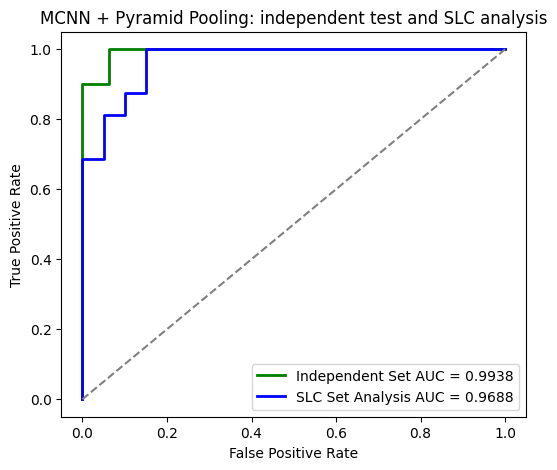

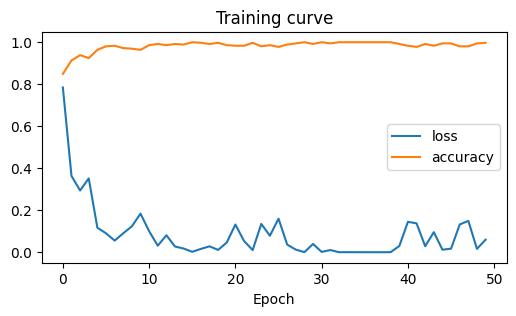

In [10]:
if VALIDATION_MODE == "independent":
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    model = build_mcnn_pyramid()
    history = model.fit({"embeddings": x_train, "length": l_train}, y_train,
                        batch_size=BATCH_SIZE, epochs=EPOCHS, shuffle=True, verbose=1)

    res_test, yt, pt = evaluate(model, x_test, l_test, y_test, "Independent test:")
    res_slc,  ys, ps = evaluate(model, x_slc,  l_slc,  y_slc,  "SLC analysis:    ")

    fpr_t, tpr_t, _ = roc_curve(yt, pt)
    fpr_s, tpr_s, _ = roc_curve(ys, ps)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr_t, tpr_t, color="green", lw=2, label=f"Independent Set AUC = {res_test['AUC']:.4f}")
    plt.plot(fpr_s, tpr_s, color="blue",  lw=2, label=f"SLC Set Analysis AUC = {res_slc['AUC']:.4f}")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("MCNN + Pyramid Pooling: independent test and SLC analysis")
    plt.legend(loc="lower right")
    plt.savefig(os.path.join(RESULT_DIR, "roc_curve_independent_pyramid.png"), dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(6, 3))
    plt.plot(history.history["loss"], label="loss"); plt.plot(history.history["accuracy"], label="accuracy")
    plt.xlabel("Epoch"); plt.legend(); plt.title("Training curve"); plt.show()

    model.save(os.path.join(RESULT_DIR, "mcnn_pyramid.keras"))
    with open(os.path.join(RESULT_DIR, "independent_results.json"), "w") as f:
        json.dump({"test": res_test, "slc": res_slc, "pyramid_levels": PYRAMID_LEVELS,
                   "window_sizes": WINDOW_SIZES}, f, indent=2)

## 8b. K-fold cross-validation (Train + Test combined, stratified)

In [11]:
if VALIDATION_MODE == "cross":
    x_all = np.concatenate([x_train, x_test]); l_all = np.concatenate([l_train, l_test])
    y_all = np.concatenate([y_train, y_test])
    del x_train, x_test; gc.collect()          # save RAM (~2 GB)

    skf = StratifiedKFold(n_splits=K_FOLD, shuffle=True, random_state=2)
    fold_results, tprs, mean_fpr = [], [], np.linspace(0, 1, 100)

    for fold, (tr, te) in enumerate(skf.split(np.zeros(len(y_all)), y_all[:, 1]), 1):
        print(f"\n========== Fold {fold}/{K_FOLD} ==========")
        keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
        model = build_mcnn_pyramid()
        model.fit({"embeddings": x_all[tr], "length": l_all[tr]}, y_all[tr],
                  batch_size=BATCH_SIZE, epochs=EPOCHS, shuffle=True, verbose=1)
        res, yt, pt = evaluate(model, x_all[te], l_all[te], y_all[te], f"Fold {fold}:")
        fold_results.append(res)
        fpr, tpr, _ = roc_curve(yt, pt)
        tprs.append(np.interp(mean_fpr, fpr, tpr)); tprs[-1][0] = 0.0
        del model; gc.collect()

    mean_tpr = np.mean(tprs, axis=0); mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    np.savetxt(os.path.join(RESULT_DIR, "roc_Prottrans_pyramid.csv"),
               np.column_stack((mean_fpr, mean_tpr, [mean_auc] * len(mean_fpr))),
               delimiter=",", header="Mean_FPR,Mean_TPR,Mean_AUC", comments="")

    print("\nAggregated metrics (mean ± std over folds):")
    for k in ["Sens", "Spec", "Acc", "MCC", "AUC", "F1"]:
        v = [r[k] for r in fold_results]
        print(f"  {k:4s} = {np.mean(v):.4f} ± {np.std(v):.4f}")
    with open(os.path.join(RESULT_DIR, "cv_results.json"), "w") as f:
        json.dump(fold_results, f, indent=2)

    plt.figure(figsize=(6, 5))
    plt.plot(mean_fpr, mean_tpr, color="darkorange", lw=2, label=f"Mean ROC (AUC = {mean_auc:.4f})")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"{K_FOLD}-fold CV ROC: MCNN + Pyramid Pooling"); plt.legend(loc="lower right")
    plt.savefig(os.path.join(RESULT_DIR, "aggregated_roc_curve_pyramid.png"), dpi=300, bbox_inches="tight")
    plt.show()

## 9. Save / download results

In [12]:
if USE_DRIVE:
    shutil.copytree(RESULT_DIR, os.path.join(DRIVE_DIR, "results"), dirs_exist_ok=True)
    print("Results copied to", os.path.join(DRIVE_DIR, "results"))

shutil.make_archive("/content/results", "zip", RESULT_DIR)
from google.colab import files
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>